# KA SS 26 · Challenge 2 — **Stage 6: domain-adapted ConvNeXt-UNet + semi-supervised learning**

This notebook keeps the strongest idea from Stage 5 — **ConvNeXt-Tiny → U-Net dense foreground/seed maps → marker-controlled watershed** — and uses the provided **1,972 unlabeled microscopy images** rather than ignoring them.

### Stage 6 plan

1. **ImageNet initialization** — `convnext_tiny.fb_in22k_ft_in1k`.
2. **Self-supervised microscopy adaptation** — short SimSiam adaptation on the provided unlabeled set. This is intentionally lightweight: the goal is domain adaptation, not training a foundation model from scratch.
3. **Supervised Stage-5-style segmentation** — foreground + eroded-seed targets, border-weighted BCE + Dice, grouped validation, EMA weights.
4. **EMA Mean Teacher consistency** — real labels remain the anchor; unlabeled images use aligned weak/strong views and only high-confidence teacher pixels contribute consistency loss.
5. **Improved watershed markers** — final grouped-validation sweep compares the original connected-component markers against local-peak markers that can split merged seed regions.
6. **Optional hard pseudo-label polish** — implemented but **OFF by default**. It should only be enabled if the Mean Teacher stage already improves grouped validation.

### Runtime target

The notebook is designed for a **single Colab T4** and uses explicit per-phase time budgets. The normal path targets roughly **75–105 minutes**, with a hard overall guard below **2 hours** including final validation, test inference, and submission writing.

### Important

- Use **Runtime → Change runtime type → T4 GPU**.
- Upload `kaggle.json` to `/content/kaggle.json` or place it in `MyDrive/ka_ss26/kaggle.json`.
- All important checkpoints are saved to Google Drive under `MyDrive/ka_ss26/stage6/`, so a disconnect should not cost the whole run.
- The test set is **never used for training or self-supervision**.

## 1 · GPU check, dependencies, imports

In [2]:
import os, sys, subprocess, math, time, json, random, gc, shutil, pickle, warnings, copy
from pathlib import Path
from collections import defaultdict, Counter

print(subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
    capture_output=True, text=True).stdout.strip() or
    "NO GPU DETECTED -> Runtime > Change runtime type > T4 GPU")

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

try:
    import timm
except ImportError:
    pip_install("timm")
    import timm

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from scipy import ndimage as ndi
from scipy.sparse import csr_matrix, csgraph
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
import cv2
import matplotlib.pyplot as plt
from torchvision import transforms

warnings.filterwarnings("ignore")
T_START = time.time()

def elapsed_seconds():
    return time.time() - T_START

def format_duration(seconds):
    seconds = max(0, float(seconds))
    return f"{int(seconds // 3600)}h {int((seconds % 3600) // 60):02d}m {int(seconds % 60):02d}s"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Enable a T4 GPU runtime before continuing."
torch.backends.cudnn.benchmark = True
try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

print("torch :", torch.__version__)
print("timm  :", timm.__version__)
print("cuda  :", torch.version.cuda)
print("device:", DEVICE)

Tesla T4, 15360 MiB, 580.82.07
torch : 2.11.0+cu128
timm  : 1.0.28
cuda  : 12.8
device: cuda


## 2 · Configuration

In [3]:
class CFG:
    SEED = 2606
    SMOKE_TEST = False
    RESUME = True

    # Hard notebook guard. Individual phases also have smaller budgets.
    TOTAL_BUDGET_SEC = 1.88 * 3600
    FINAL_RESERVE_SEC = 14 * 60
    SSL_BUDGET_SEC = 15 * 60
    SUP_BUDGET_SEC = 46 * 60
    SEMI_BUDGET_SEC = 27 * 60

    # Data / geometry. Actual image size is detected from disk.
    IMG_H, IMG_W = 520, 704
    PAD_H, PAD_W = 544, 704
    CROP_H, CROP_W = 448, 576

    # Honest split copied from the Stage 5 philosophy.
    GROUP_SPLIT = True
    DUP_CORR_THR = 0.72
    N_FOLDS = 5
    FOLD = 0
    CLUSTER_K_RANGE = (2, 3, 4, 5)

    # Shared backbone / segmentation architecture.
    ENCODER = "convnext_tiny.fb_in22k_ft_in1k"
    ENCODER_FALLBACKS = ("convnext_tiny", "resnet34")
    DECODER_CHANNELS = (256, 128, 64, 32)
    OUT_CHANNELS = 2  # foreground, eroded seed

    # Targets.
    SEED_EROSION_FRAC = 0.45
    BORDER_DILATION = 2
    BORDER_WEIGHT = 4.0

    # A) self-supervised domain adaptation (SimSiam).
    SSL_EPOCHS = 8
    SSL_SIZE = 224
    SSL_BATCH_SIZE = 32
    SSL_LR = 1.5e-4
    SSL_WEIGHT_DECAY = 1e-4
    SSL_PROJ_DIM = 256
    SSL_HIDDEN_DIM = 768

    # B) supervised segmentation.
    SUP_EPOCHS = 45
    SUP_BATCH_SIZE = 8
    SUP_LR = 3e-4
    SUP_ENCODER_LR_MULT = 0.20
    SUP_WEIGHT_DECAY = 1e-4
    SUP_FREEZE_ENCODER_EPOCHS = 1
    SUP_WARMUP_STEPS = 120
    SUP_EVAL_START = 6
    SUP_EVAL_EVERY = 3
    SUP_EMA_DECAY = 0.999

    # C) Mean Teacher consistency. Keep it short and conservative.
    SEMI_EPOCHS = 10
    SEMI_BATCH_LABELED = 6
    SEMI_BATCH_UNLABELED = 6
    SEMI_STEPS_PER_EPOCH = 42
    SEMI_LR = 8e-5
    SEMI_ENCODER_LR_MULT = 0.25
    TEACHER_EMA_DECAY = 0.995
    CONSISTENCY_LAMBDA_MAX = 0.50
    CONSISTENCY_POS_THR = 0.80
    CONSISTENCY_NEG_THR = 0.05
    CONSISTENCY_NEG_WEIGHT = 0.05
    SEMI_EVAL_EVERY = 2

    # Optional D) hard pseudo-label polish. OFF intentionally.
    RUN_HARD_PSEUDO = False
    PSEUDO_EPOCHS = 3
    PSEUDO_LAMBDA = 0.20

    # Shared optimisation / augmentation.
    AMP = True
    NUM_WORKERS = 2
    GRAD_CLIP = 5.0
    AUG_HFLIP = 0.5
    AUG_VFLIP = 0.5
    AUG_ROT90 = 0.5
    AUG_SCALE = 0.5
    AUG_SCALE_RANGE = (0.85, 1.20)
    AUG_BRIGHTNESS_CONTRAST = 0.5
    AUG_GAMMA = 0.3
    AUG_NOISE = 0.2

    # Quick checkpoint validation uses the Stage-5 neighborhood.
    QUICK_T_CELL = 0.55
    QUICK_T_SEED = 0.65
    DICE_MATCH_THR = 0.50

    # Final TTA + focused post-processing sweep.
    TTA_FLIPS = True
    SWEEP_T_CELL = (0.50, 0.55, 0.60)
    SWEEP_T_SEED = (0.55, 0.65, 0.75)
    SWEEP_MARKERS = (("cc", 0), ("peaks", 5), ("peaks", 7))
    SWEEP_MIN_AREA_Q = (0.01, 0.03, 0.05, 0.10)

    SUB_INDEX_COL = "idx"
    RUN_TAG = "stage6_ssl_mean_teacher_convnext_unet_ws"
    SAVE_CACHES = True

if CFG.SMOKE_TEST:
    CFG.SSL_EPOCHS = 1
    CFG.SUP_EPOCHS = 2
    CFG.SEMI_EPOCHS = 1
    CFG.SEMI_STEPS_PER_EPOCH = 4
    CFG.SUP_EVAL_START = 1
    CFG.SUP_EVAL_EVERY = 1

seed_everything(CFG.SEED)
STATS = {}
print("overall budget:", format_duration(CFG.TOTAL_BUDGET_SEC))
print("planned phases : SSL", CFG.SSL_EPOCHS, "epochs | supervised", CFG.SUP_EPOCHS,
      "| semi-supervised", CFG.SEMI_EPOCHS)

overall budget: 1h 52m 48s
planned phases : SSL 8 epochs | supervised 45 | semi-supervised 10


## 3 · Google Drive + Kaggle API data access

The cell accepts Kaggle credentials from either `/content/kaggle.json` or `MyDrive/ka_ss26/kaggle.json`. Data are downloaded only when they are not already extracted in the Colab runtime. Checkpoints live in Drive.

In [4]:
from google.colab import drive
import zipfile

drive.mount("/content/drive", force_remount=False)

KAGGLE_COMPETITION = "ka-ss-26-challenge-2"
DRIVE_WORKDIR = Path("/content/drive/MyDrive/ka_ss26/stage6")
WORK = DRIVE_WORKDIR
ART = WORK / "artifacts"
CKPT = WORK / "ckpt"
DATA_ROOT = Path("/content/data")
for p in (WORK, ART, CKPT, DATA_ROOT):
    p.mkdir(parents=True, exist_ok=True)

credential_candidates = [
    Path("/content/kaggle.json"),
    Path("/content/drive/MyDrive/ka_ss26/kaggle.json"),
]
KAGGLE_JSON = next((p for p in credential_candidates if p.is_file()), None)
assert KAGGLE_JSON is not None, (
    "Missing kaggle.json. Upload it to /content/kaggle.json or place it at "
    "MyDrive/ka_ss26/kaggle.json."
)
print("credentials:", KAGGLE_JSON)
print("work dir   :", WORK)

def looks_like_dataset(path: Path) -> bool:
    return (path / "train.csv").is_file() and (path / "train").is_dir() and (path / "test").is_dir()

def find_dataset_root(base: Path):
    if looks_like_dataset(base):
        return base
    for csv_path in base.rglob("train.csv"):
        if looks_like_dataset(csv_path.parent):
            return csv_path.parent
    return None

BASE = find_dataset_root(DATA_ROOT)
if BASE is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"], check=True)
    kaggle_dir = Path("/root/.kaggle")
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    installed_json = kaggle_dir / "kaggle.json"
    shutil.copy2(KAGGLE_JSON, installed_json)
    installed_json.chmod(0o600)

    for old_zip in DATA_ROOT.glob("*.zip"):
        old_zip.unlink(missing_ok=True)

    print("Downloading competition data...")
    result = subprocess.run(
        ["kaggle", "competitions", "download", "-c", KAGGLE_COMPETITION,
         "-p", str(DATA_ROOT), "--force"], capture_output=True, text=True)
    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Kaggle download failed. Join the competition and accept its rules first.")

    archives = sorted(DATA_ROOT.glob("*.zip"))
    assert archives, "No competition ZIP was downloaded."
    for archive in archives:
        assert zipfile.is_zipfile(archive), f"Invalid ZIP: {archive}"
        print("Extracting", archive.name)
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(DATA_ROOT)
    BASE = find_dataset_root(DATA_ROOT)

assert BASE is not None, "Could not find train.csv, train/, and test/ after extraction."
TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"
TRAIN_CSV = BASE / "train.csv"

# Robustly discover every provided PNG outside train/ and test/ as unlabeled data.
all_png = sorted(BASE.rglob("*.png"))
UNLABELED_PATHS = [p for p in all_png if TRAIN_DIR not in p.parents and TEST_DIR not in p.parents]

print("dataset root     :", BASE)
print("train images     :", len(list(TRAIN_DIR.glob("*.png"))))
print("test images      :", len(list(TEST_DIR.glob("*.png"))))
print("unlabeled images :", len(UNLABELED_PATHS))
if UNLABELED_PATHS:
    print("unlabeled example:", UNLABELED_PATHS[0])

assert len(list(TRAIN_DIR.glob("*.png"))) == 424, "Expected 424 labeled train images."
assert len(list(TEST_DIR.glob("*.png"))) == 182, "Expected 182 test images."
assert len(UNLABELED_PATHS) > 0, "No provided unlabeled PNGs were discovered."
if len(UNLABELED_PATHS) != 1972:
    print(f"WARNING: expected ~1972 unlabeled images from EDA, found {len(UNLABELED_PATHS)}. Continuing.")

STATS["n_unlabeled"] = len(UNLABELED_PATHS)

Mounted at /content/drive
credentials: /content/kaggle.json
work dir   : /content/drive/MyDrive/ka_ss26/stage6


Extracting ka-ss-26-challenge-2.zip
dataset root     : /content/data/cells_segmentation
train images     : 424
test images      : 182
unlabeled images : 1972
unlabeled example: /content/data/cells_segmentation/unlabeled_additional_data/0.png


## 4 · Schema, inventory, and quick domain audit

columns: ['Unnamed: 0', 'id', 'annotation'] | rows: 53065
image size HxW = 520x704 -> padded 544x704
sampled mean/std
  labeled  : (0.5018, 0.0524)
  unlabeled: (0.5019, 0.0446)
  test     : (0.5018, 0.0511)


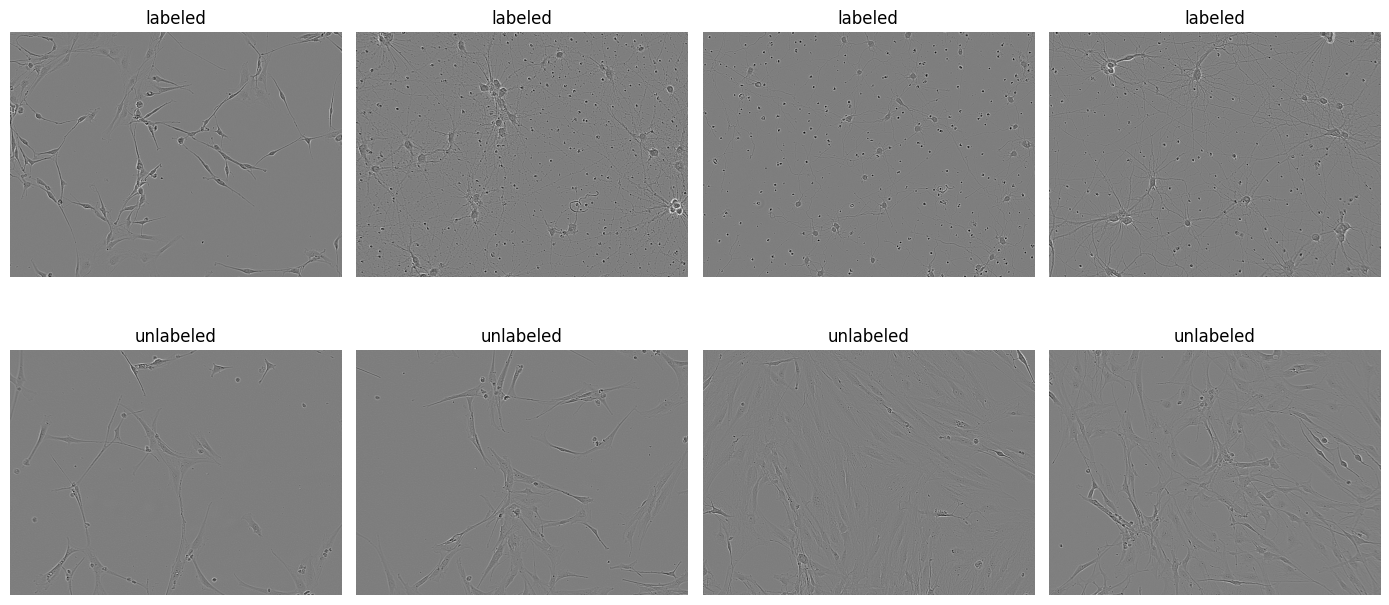

In [5]:
df_raw = pd.read_csv(TRAIN_CSV)
print("columns:", df_raw.columns.tolist(), "| rows:", len(df_raw))
ID_COL = next(c for c in df_raw.columns if c.lower() in ("id", "image_id", "imageid"))
ANN_COL = next(c for c in df_raw.columns if c.lower() in ("annotation", "encodedpixels", "rle", "segmentation"))

TRAIN_IDS = sorted(p.stem for p in TRAIN_DIR.glob("*.png"))
TEST_IDS = sorted(p.stem for p in TEST_DIR.glob("*.png"))
with Image.open(TRAIN_DIR / f"{TRAIN_IDS[0]}.png") as im:
    CFG.IMG_W, CFG.IMG_H = im.size
CFG.PAD_H = int(math.ceil(CFG.IMG_H / 32) * 32)
CFG.PAD_W = int(math.ceil(CFG.IMG_W / 32) * 32)
NPIX = CFG.IMG_H * CFG.IMG_W
print(f"image size HxW = {CFG.IMG_H}x{CFG.IMG_W} -> padded {CFG.PAD_H}x{CFG.PAD_W}")

def load_gray_u8(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L"), dtype=np.uint8)

IMAGES = {i: load_gray_u8(TRAIN_DIR / f"{i}.png") for i in TRAIN_IDS}

def sampled_stats(paths, max_n=200, seed=0):
    rng = np.random.RandomState(seed)
    paths = list(paths)
    if len(paths) > max_n:
        paths = [paths[i] for i in rng.choice(len(paths), max_n, replace=False)]
    means, stds = [], []
    for p in paths:
        a = load_gray_u8(p).astype(np.float32) / 255.0
        means.append(a.mean()); stds.append(a.std())
    return float(np.mean(means)), float(np.mean(stds))

train_stat = sampled_stats([TRAIN_DIR / f"{i}.png" for i in TRAIN_IDS])
unlab_stat = sampled_stats(UNLABELED_PATHS)
test_stat = sampled_stats([TEST_DIR / f"{i}.png" for i in TEST_IDS])
print("sampled mean/std")
print("  labeled  :", tuple(round(x, 4) for x in train_stat))
print("  unlabeled:", tuple(round(x, 4) for x in unlab_stat))
print("  test     :", tuple(round(x, 4) for x in test_stat))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, image_id in zip(axes[0], TRAIN_IDS[:4]):
    ax.imshow(IMAGES[image_id], cmap="gray"); ax.set_title("labeled"); ax.axis("off")
for ax, path in zip(axes[1], UNLABELED_PATHS[:4]):
    ax.imshow(load_gray_u8(path), cmap="gray"); ax.set_title("unlabeled"); ax.axis("off")
plt.tight_layout(); plt.show()

SUB_PATH = Path("/content/stage6_submission.csv")
STATS.update(n_train_images=len(TRAIN_IDS), n_test_images=len(TEST_IDS), image_hw=[CFG.IMG_H, CFG.IMG_W])

## 5 · RLE decode/encode and annotation cache

In [6]:
def rle_decode_flat(rle, h, w, order="C"):
    if not isinstance(rle, str) or not rle.strip() or rle.strip() == "-1":
        return np.empty(0, dtype=np.int64)
    values = np.asarray(rle.split(), dtype=np.int64)
    starts, lengths = values[0::2] - 1, values[1::2]
    idx = np.concatenate([np.arange(s, s + l) for s, l in zip(starts, lengths)])
    if order == "C":
        return idx
    return (idx % h) * w + (idx // h)

def rle_encode(mask_bool):
    pixels = np.concatenate([[0], mask_bool.reshape(-1).astype(np.uint8), [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[0::2]
    return " ".join(str(int(x)) for x in runs)

def flat_to_rle(flat):
    mask = np.zeros(NPIX, dtype=np.uint8)
    mask[flat] = 1
    return rle_encode(mask)

probe = df_raw[df_raw[ANN_COL].astype(str) != "-1"].sample(min(200, len(df_raw)), random_state=0)
order_report = {}
for order in ("C", "F"):
    single, fill = [], []
    for rle in probe[ANN_COL].astype(str):
        flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, order)
        if flat.size == 0 or flat.max() >= NPIX:
            continue
        mask = np.zeros(NPIX, bool); mask[flat] = True
        mask = mask.reshape(CFG.IMG_H, CFG.IMG_W)
        single.append(ndi.label(mask)[1] == 1)
        ys, xs = np.nonzero(mask)
        fill.append(mask.sum() / ((ys.max()-ys.min()+1) * (xs.max()-xs.min()+1)))
    order_report[order] = (float(np.mean(single) * 100), float(np.mean(fill)))
print("order report:", order_report)
RLE_ORDER = max(order_report, key=lambda o: order_report[o])
print(">>> detected RLE order:", RLE_ORDER)

INST = defaultdict(list)
bad = 0
for image_id, rle in zip(df_raw[ID_COL].astype(str), df_raw[ANN_COL].astype(str)):
    flat = rle_decode_flat(rle, CFG.IMG_H, CFG.IMG_W, RLE_ORDER)
    if flat.size == 0 or flat.max() >= NPIX:
        bad += 1
        continue
    INST[image_id].append(flat.astype(np.int32))

counts = np.asarray([len(INST[i]) for i in TRAIN_IDS if i in INST])
areas = np.asarray([f.size for v in INST.values() for f in v])
print("decoded instances:", len(areas), "| skipped rows:", bad)
print("instances/image p50/p95/p99/max:", *[int(np.percentile(counts, p)) for p in (50,95,99)], int(counts.max()))
print("area p1/p5/p50/p95:", *[int(np.percentile(areas, p)) for p in (1,5,50,95)])
MIN_AREA_GRID = sorted({int(np.percentile(areas, q * 100)) for q in CFG.SWEEP_MIN_AREA_Q})
print("final min-area grid:", MIN_AREA_GRID)
STATS.update(rle_order=RLE_ORDER, max_instances=int(counts.max()))

order report: {'C': (91.5, 0.5815406671870815), 'F': (0.0, 0.019448349777179116)}
>>> detected RLE order: C
decoded instances: 53065 | skipped rows: 0
instances/image p50/p95/p99/max: 47 503 592 782
area p1/p5/p50/p95: 53 82 215 920
final min-area grid: [53, 71, 82, 103]


## 6 · Official metric

In [7]:
def sparse_masks(flats, npix):
    if len(flats) == 0:
        return csr_matrix((0, npix), dtype=np.float32)
    indptr = np.zeros(len(flats) + 1, dtype=np.int64)
    indptr[1:] = np.cumsum([len(f) for f in flats])
    indices = np.concatenate(flats).astype(np.int64)
    return csr_matrix((np.ones(indices.size, np.float32), indices, indptr), shape=(len(flats), npix))

def dice_matrix(gt_flats, pred_flats, npix=None):
    npix = NPIX if npix is None else npix
    if len(gt_flats) == 0 or len(pred_flats) == 0:
        return np.zeros((len(gt_flats), len(pred_flats)), dtype=np.float32)
    gt_sparse, pred_sparse = sparse_masks(gt_flats, npix), sparse_masks(pred_flats, npix)
    intersection = (gt_sparse @ pred_sparse.T).toarray()
    gt_area = np.asarray(gt_sparse.sum(axis=1)).reshape(-1, 1)
    pred_area = np.asarray(pred_sparse.sum(axis=1)).reshape(1, -1)
    return (2.0 * intersection / np.maximum(gt_area + pred_area, 1.0)).astype(np.float32)

def greedy_match(dice, threshold=0.50):
    work = np.asarray(dice, dtype=np.float32).copy()
    if work.size == 0:
        return 0
    tp = 0
    while True:
        k = int(np.argmax(work))
        if float(work.flat[k]) < threshold:
            break
        i, j = np.unravel_index(k, work.shape)
        tp += 1
        work[i, :] = -1.0
        work[:, j] = -1.0
    return tp

def instance_f1_from_dice(dice, threshold=0.50):
    n_gt, n_pred = dice.shape
    if n_gt == 0 and n_pred == 0: return 1.0
    if n_gt == 0 or n_pred == 0: return 0.0
    tp = greedy_match(dice, threshold)
    return 2.0 * tp / (2.0 * tp + (n_pred - tp) + (n_gt - tp) + 1e-8)

def score_dataset_f1(gt_by_id, pred_by_id, threshold=0.50):
    return float(np.mean([
        instance_f1_from_dice(dice_matrix(gt, pred_by_id.get(image_id, [])), threshold)
        for image_id, gt in gt_by_id.items()
    ])) if gt_by_id else 0.0

_a = np.array([0,1,2], dtype=np.int32)
_b = np.array([10,11], dtype=np.int32)
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a]}) - 1.0) < 1e-7
assert abs(score_dataset_f1({"x": [_a]}, {"x": [_a, _a]}) - 2/3) < 1e-7
assert abs(score_dataset_f1({"x": [_a, _b]}, {"x": [_a, _b]}) - 1.0) < 1e-7
print("official metric unit tests passed")

official metric unit tests passed


## 7 · Near-duplicate grouping and grouped validation

In [8]:
labeled_ids = [i for i in TRAIN_IDS if i in INST]

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def image_features(arr):
    a = arr.astype(np.float32)
    hist = np.histogram(a, bins=24, range=(0,255))[0].astype(np.float32)
    hist /= max(hist.sum(), 1.0)
    return np.concatenate([[a.mean(), a.std(), float(ndi.laplace(a).var()),
                            float(np.abs(np.diff(a, axis=0)).mean()),
                            float(np.abs(np.diff(a, axis=1)).mean())], hist])

feature_ids = TRAIN_IDS + TEST_IDS
feature_matrix = np.stack([
    image_features(IMAGES[i]) if i in IMAGES else image_features(load_gray_u8(TEST_DIR / f"{i}.png"))
    for i in feature_ids
])
reduced = PCA(n_components=5, random_state=CFG.SEED).fit_transform(StandardScaler().fit_transform(feature_matrix))
silhouettes = {}
for k in CFG.CLUSTER_K_RANGE:
    labels = KMeans(k, n_init=10, random_state=CFG.SEED).fit_predict(reduced)
    silhouettes[k] = float(silhouette_score(reduced, labels))
BEST_K = max(silhouettes, key=silhouettes.get)
CLUSTER = dict(zip(feature_ids, KMeans(BEST_K, n_init=10, random_state=CFG.SEED).fit_predict(reduced).tolist()))
print("silhouette:", {k: round(v,3) for k,v in silhouettes.items()}, "-> k", BEST_K)

thumbs = []
for image_id in labeled_ids:
    small = cv2.resize(IMAGES[image_id].astype(np.float32), (88,65), interpolation=cv2.INTER_AREA)
    small -= small.mean()
    thumbs.append((small / (np.linalg.norm(small) + 1e-6)).ravel())
THUMBS = np.stack(thumbs)
CORR = THUMBS @ THUMBS.T
np.fill_diagonal(CORR, 0.0)
n_groups, group_of = csgraph.connected_components(csr_matrix(CORR >= CFG.DUP_CORR_THR), directed=False)
GROUP = dict(zip(labeled_ids, group_of.tolist()))
print("groups:", n_groups, "over", len(labeled_ids), "images")
print("group-size histogram:", dict(sorted(Counter(Counter(group_of.tolist()).values()).items())))

group_members = defaultdict(list)
for image_id in labeled_ids:
    group_members[GROUP[image_id] if CFG.GROUP_SPLIT else image_id].append(image_id)
group_density = {g: float(np.mean([len(INST[i]) for i in m])) for g,m in group_members.items()}
edges = np.percentile(list(group_density.values()), [33,66])
buckets = defaultdict(list)
for g, members in group_members.items():
    cluster = Counter(CLUSTER.get(i,-1) for i in members).most_common(1)[0][0]
    buckets[f"{cluster}_{int(np.digitize(group_density[g], edges))}"].append(g)

rng = np.random.RandomState(CFG.SEED)
fold_of_group, counter = {}, 0
for stratum in sorted(buckets):
    groups = sorted(buckets[stratum]); rng.shuffle(groups)
    for g in groups:
        fold_of_group[g] = counter % CFG.N_FOLDS
        counter += 1

val_ids = sorted(i for g,m in group_members.items() if fold_of_group[g] == CFG.FOLD for i in m)
train_ids = sorted(set(labeled_ids) - set(val_ids))
if CFG.SMOKE_TEST:
    train_ids, val_ids = train_ids[:24], val_ids[:10]
GT_VAL = {i: INST[i] for i in val_ids}

index_of = {i:k for k,i in enumerate(labeled_ids)}
cross = CORR[np.ix_([index_of[i] for i in val_ids], [index_of[i] for i in train_ids])]
print(f"train {len(train_ids)} | val {len(val_ids)} | fold {CFG.FOLD}/{CFG.N_FOLDS}")
print("val cluster mix:", dict(Counter(CLUSTER.get(i,-1) for i in val_ids)))
print("max val-to-train correlation:", round(float(cross.max()), 3))
STATS.update(n_groups=int(n_groups), fold=int(CFG.FOLD), max_val_train_corr=float(cross.max()),
             n_train=len(train_ids), n_val=len(val_ids))

silhouette: {2: 0.405, 3: 0.36, 4: 0.363, 5: 0.342} -> k 2
groups: 424 over 424 images
group-size histogram: {1: 424}
train 339 | val 85 | fold 0/5
val cluster mix: {0: 45, 1: 40}
max val-to-train correlation: 0.553


## 8 · Stage-5 foreground / seed / contact-zone targets

targets built in 21s | memory 466 MB


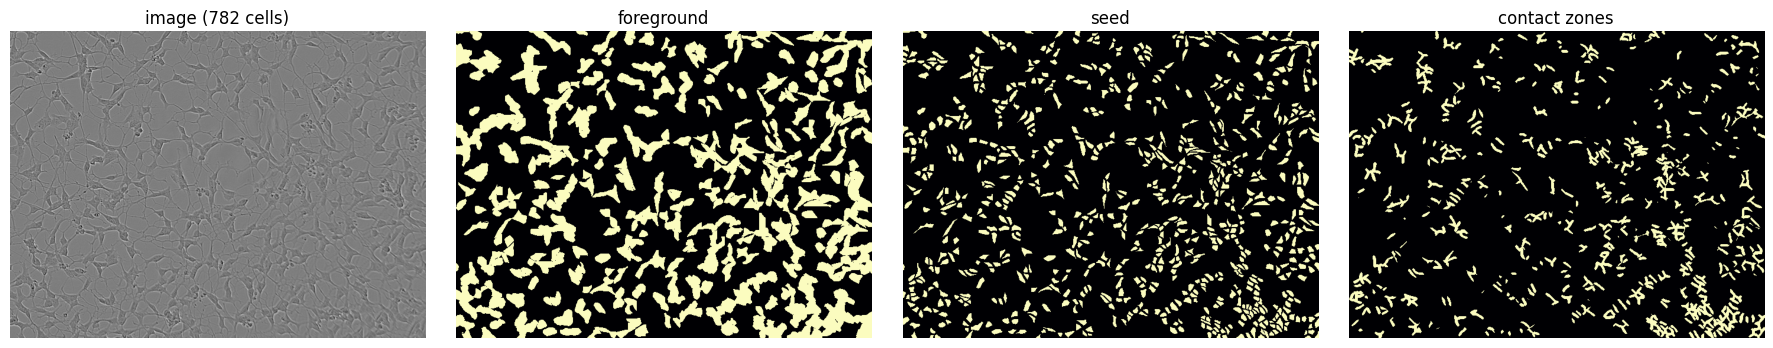

In [9]:
def build_targets(image_id):
    h, w = CFG.IMG_H, CFG.IMG_W
    foreground = np.zeros((h,w), np.uint8)
    seed = np.zeros((h,w), np.uint8)
    overlap_count = np.zeros((h,w), np.uint16)
    pad = CFG.BORDER_DILATION + 1
    for flat in INST[image_id]:
        ys, xs = np.divmod(flat.astype(np.int64), w)
        y0, y1 = max(0, ys.min()-pad), min(h, ys.max()+1+pad)
        x0, x1 = max(0, xs.min()-pad), min(w, xs.max()+1+pad)
        patch = np.zeros((y1-y0, x1-x0), np.uint8)
        patch[ys-y0, xs-x0] = 1
        foreground[y0:y1, x0:x1] |= patch
        distance = ndi.distance_transform_edt(patch)
        core = (distance > max(1.0, CFG.SEED_EROSION_FRAC * distance.max())).astype(np.uint8)
        seed[y0:y1, x0:x1] |= (core if core.any() else patch)
        overlap_count[y0:y1, x0:x1] += ndi.binary_dilation(
            patch, iterations=CFG.BORDER_DILATION).astype(np.uint16)
    border = (overlap_count > 1).astype(np.uint8)
    return np.stack([foreground, seed, border])

t0 = time.time()
TARGETS = {i: build_targets(i) for i in labeled_ids}
print(f"targets built in {time.time()-t0:.0f}s | memory {sum(t.nbytes for t in TARGETS.values())/1e6:.0f} MB")

demo = max(train_ids, key=lambda i: len(INST[i]))
fig, axes = plt.subplots(1,4,figsize=(18,3.4))
for ax, (title, arr) in zip(axes, [
    (f"image ({len(INST[demo])} cells)", IMAGES[demo]),
    ("foreground", TARGETS[demo][0]), ("seed", TARGETS[demo][1]), ("contact zones", TARGETS[demo][2])]):
    ax.imshow(arr, cmap="gray" if title.startswith("image") else "magma")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 9 · Datasets and augmentations

In [10]:
def pad_to(arr, height, width, mode="reflect"):
    ph, pw = height - arr.shape[-2], width - arr.shape[-1]
    if ph == 0 and pw == 0:
        return arr
    pad_width = [(0,0)] * (arr.ndim - 2) + [(0,ph), (0,pw)]
    return np.pad(arr, pad_width, mode=mode)

def to_3ch_tensor(image):
    return torch.from_numpy(np.ascontiguousarray(image.astype(np.float32))).unsqueeze(0).repeat(3,1,1)

class CellDataset(Dataset):
    def __init__(self, ids, training=True):
        self.ids = list(ids); self.training = bool(training)
    def __len__(self): return len(self.ids)
    def __getitem__(self, index):
        image_id = self.ids[index]
        image = IMAGES[image_id].astype(np.float32) / 255.0
        target = TARGETS[image_id].copy()
        if self.training:
            image, target = self.augment(image, target)
            image, target = self.random_crop(image, target)
        else:
            image = pad_to(image, CFG.PAD_H, CFG.PAD_W)
            target = pad_to(target, CFG.PAD_H, CFG.PAD_W, mode="constant")
        weight = 1.0 + CFG.BORDER_WEIGHT * target[2].astype(np.float32)
        return to_3ch_tensor(image), torch.from_numpy(np.ascontiguousarray(target[:2]).astype(np.float32)), \
               torch.from_numpy(weight).unsqueeze(0), image_id
    def augment(self, image, target):
        if random.random() < CFG.AUG_HFLIP:
            image, target = image[:, ::-1], target[:, :, ::-1]
        if random.random() < CFG.AUG_VFLIP:
            image, target = image[::-1, :], target[:, ::-1, :]
        if random.random() < CFG.AUG_ROT90:
            k = random.choice((1,2,3)); image = np.rot90(image, k); target = np.rot90(target, k, axes=(1,2))
        image, target = np.ascontiguousarray(image), np.ascontiguousarray(target)
        if random.random() < CFG.AUG_SCALE:
            scale = random.uniform(*CFG.AUG_SCALE_RANGE)
            new_size = (max(32, int(round(image.shape[1]*scale))), max(32, int(round(image.shape[0]*scale))))
            image = cv2.resize(image, new_size, interpolation=cv2.INTER_LINEAR)
            target = np.stack([cv2.resize(t, new_size, interpolation=cv2.INTER_NEAREST) for t in target])
        if random.random() < CFG.AUG_BRIGHTNESS_CONTRAST:
            image = np.clip((image-0.5)*random.uniform(0.85,1.18)+0.5+random.uniform(-0.10,0.10), 0,1)
        if random.random() < CFG.AUG_GAMMA:
            image = np.clip(image,1e-4,1.0) ** random.uniform(0.75,1.35)
        if random.random() < CFG.AUG_NOISE:
            image = np.clip(image + np.random.normal(0, random.uniform(0.005,0.02), image.shape), 0,1)
        return image.astype(np.float32), target
    def random_crop(self, image, target):
        h,w = CFG.CROP_H, CFG.CROP_W
        image = pad_to(image, max(h,image.shape[0]), max(w,image.shape[1]))
        target = pad_to(target, max(h,target.shape[1]), max(w,target.shape[2]), mode="constant")
        top = random.randint(0, image.shape[0]-h); left = random.randint(0, image.shape[1]-w)
        return image[top:top+h,left:left+w], target[:,top:top+h,left:left+w]

class RandomQuarterTurn:
    def __call__(self, image):
        k = random.choice((0,1,2,3))
        if k == 0: return image
        return image.rotate(90*k, expand=False)

ssl_transform = transforms.Compose([
    transforms.RandomResizedCrop((CFG.SSL_SIZE, CFG.SSL_SIZE), scale=(0.55,1.0), ratio=(0.85,1.15), antialias=True),
    RandomQuarterTurn(), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomApply([transforms.ColorJitter(brightness=0.25, contrast=0.30)], p=0.8),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1,1.2))], p=0.25),
    transforms.RandomAutocontrast(p=0.15), transforms.ToTensor(),
])

class SSLDataset(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as im:
            image = im.convert("L").convert("RGB")
            return ssl_transform(image), ssl_transform(image)

def shared_geometry(image):
    if random.random() < 0.5: image = image[:, ::-1]
    if random.random() < 0.5: image = image[::-1, :]
    if random.random() < 0.5: image = np.rot90(image, random.choice((1,2,3)))
    image = np.ascontiguousarray(image)
    if random.random() < 0.5:
        scale = random.uniform(0.88,1.15)
        new_size = (max(32,int(round(image.shape[1]*scale))), max(32,int(round(image.shape[0]*scale))))
        image = cv2.resize(image, new_size, interpolation=cv2.INTER_LINEAR)
    h,w = CFG.CROP_H, CFG.CROP_W
    image = pad_to(image, max(h,image.shape[0]), max(w,image.shape[1]))
    top = random.randint(0, image.shape[0]-h); left = random.randint(0, image.shape[1]-w)
    return image[top:top+h,left:left+w].astype(np.float32)

def weak_photo(x):
    x = np.clip((x-0.5)*random.uniform(0.94,1.06)+0.5+random.uniform(-0.025,0.025),0,1)
    if random.random() < 0.25: x = np.clip(x,1e-4,1) ** random.uniform(0.92,1.08)
    return x.astype(np.float32)

def strong_photo(x):
    x = np.clip((x-0.5)*random.uniform(0.76,1.24)+0.5+random.uniform(-0.09,0.09),0,1)
    if random.random() < 0.65: x = np.clip(x,1e-4,1) ** random.uniform(0.72,1.38)
    if random.random() < 0.50: x = np.clip(x + np.random.normal(0,random.uniform(0.006,0.025),x.shape),0,1)
    if random.random() < 0.20: x = cv2.GaussianBlur(x,(3,3),random.uniform(0.2,0.8))
    return x.astype(np.float32)

class AlignedUnlabeledDataset(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self,index):
        image = load_gray_u8(self.paths[index]).astype(np.float32)/255.0
        base = shared_geometry(image)
        return to_3ch_tensor(weak_photo(base.copy())), to_3ch_tensor(strong_photo(base.copy()))

print("datasets ready")

datasets ready


## 10 · Model, losses, inference, and improved watershed decoding

In [11]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels,out_channels,3,padding=1,bias=False), nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True))
    def forward(self,x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, encoder_name, out_channels, decoder_channels, pretrained=False):
        super().__init__()
        self.encoder = timm.create_model(encoder_name, pretrained=pretrained, features_only=True, in_chans=3)
        channels = self.encoder.feature_info.channels()
        self.reductions = self.encoder.feature_info.reduction()
        blocks, in_ch = [], channels[-1]
        for i in range(len(channels)-1):
            out_ch = decoder_channels[min(i,len(decoder_channels)-1)]
            blocks.append(ConvBlock(in_ch + channels[-2-i], out_ch)); in_ch = out_ch
        self.decoder = nn.ModuleList(blocks)
        self.stem = nn.Sequential(nn.Conv2d(3,16,3,padding=1,bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.head = nn.Sequential(ConvBlock(in_ch+16,32), nn.Conv2d(32,out_channels,1))
    def set_encoder_trainable(self, flag):
        for p in self.encoder.parameters(): p.requires_grad = bool(flag)
    def forward(self,x):
        feats = self.encoder(x); y = feats[-1]
        for i,block in enumerate(self.decoder):
            skip = feats[-2-i]
            y = F.interpolate(y,size=skip.shape[-2:],mode="nearest")
            y = block(torch.cat([y,skip],dim=1))
        y = F.interpolate(y,size=x.shape[-2:],mode="bilinear",align_corners=False)
        return self.head(torch.cat([y,self.stem(x)],dim=1))

def amp_autocast():
    try: return torch.autocast("cuda", enabled=CFG.AMP)
    except (AttributeError,TypeError): return torch.cuda.amp.autocast(enabled=CFG.AMP)

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=CFG.AMP)
    except (AttributeError,TypeError): return torch.cuda.amp.GradScaler(enabled=CFG.AMP)

def make_adamw(groups, lr, weight_decay):
    try: return torch.optim.AdamW(groups, lr=lr, weight_decay=weight_decay, fused=True)
    except Exception: return torch.optim.AdamW(groups, lr=lr, weight_decay=weight_decay)

def supervised_loss(logits,target,weight):
    bce = F.binary_cross_entropy_with_logits(logits,target,reduction="none")
    bce = (bce*weight).mean()
    probs = torch.sigmoid(logits); dims=(0,2,3)
    intersection = (probs*target).sum(dims)
    denominator = probs.sum(dims)+target.sum(dims)
    dice = 1.0-(2.0*intersection+1.0)/(denominator+1.0)
    return bce+dice.mean()

class EMAWeights:
    def __init__(self, model, decay):
        self.decay=decay
        self.shadow={k:(v.detach().clone().float() if v.dtype.is_floating_point else v.detach().clone())
                     for k,v in model.state_dict().items()}
    def update(self,model):
        for k,v in model.state_dict().items():
            if v.dtype.is_floating_point:
                self.shadow[k].mul_(self.decay).add_(v.detach().float(),alpha=1.0-self.decay)
            else: self.shadow[k]=v.detach().clone()
    def state_dict(self): return {k:v.clone() for k,v in self.shadow.items()}

def ensure_foreground_markers(markers, foreground, seed_prob):
    markers = markers.astype(np.int32, copy=True)
    next_id = int(markers.max()) + 1
    fg_cc, n_fg = ndi.label(foreground)
    for lab in range(1,n_fg+1):
        comp = fg_cc == lab
        if np.any(markers[comp] > 0):
            continue
        ys,xs = np.nonzero(comp)
        if len(ys)==0: continue
        k = int(np.argmax(seed_prob[ys,xs]))
        markers[ys[k],xs[k]] = next_id; next_id += 1
    return markers

def make_markers(seed_prob, foreground, t_seed, mode="cc", min_distance=5):
    seed_mask = np.logical_and(seed_prob >= t_seed, foreground)
    if mode == "cc":
        markers,_ = ndi.label(seed_mask)
        return ensure_foreground_markers(markers, foreground, seed_prob)

    # Peak markers split a connected seed region when it contains multiple strong local maxima.
    smooth = ndi.gaussian_filter(seed_prob.astype(np.float32), sigma=1.0)
    coords = peak_local_max(smooth, min_distance=int(min_distance), threshold_abs=float(t_seed),
                            labels=seed_mask.astype(np.uint8), exclude_border=False)
    markers = np.zeros(seed_prob.shape, np.int32)
    marker_id = 1
    for y,x in coords:
        markers[int(y),int(x)] = marker_id; marker_id += 1

    # Ensure every thresholded seed component has at least one marker.
    seed_cc,n_seed = ndi.label(seed_mask)
    for lab in range(1,n_seed+1):
        comp = seed_cc == lab
        if np.any(markers[comp] > 0): continue
        ys,xs = np.nonzero(comp)
        if len(ys)==0: continue
        k = int(np.argmax(seed_prob[ys,xs]))
        markers[ys[k],xs[k]] = marker_id; marker_id += 1
    return ensure_foreground_markers(markers, foreground, seed_prob)

def decode_instances(fg_prob, seed_prob, t_cell, t_seed, min_area=0, marker_mode="cc", min_distance=5):
    foreground = fg_prob >= t_cell
    if not foreground.any(): return []
    markers = make_markers(seed_prob, foreground, t_seed, marker_mode, min_distance)
    if markers.max() == 0: return []
    labels = watershed(-fg_prob, markers=markers, mask=foreground)
    flat_labels = labels.reshape(-1); nonzero = np.flatnonzero(flat_labels)
    if nonzero.size == 0: return []
    values = flat_labels[nonzero]; order = np.argsort(values,kind="stable")
    nonzero,values = nonzero[order],values[order]
    splits = np.flatnonzero(np.diff(values))+1; flat_fg=fg_prob.reshape(-1)
    instances=[]
    for group in np.split(nonzero,splits):
        if group.size < min_area: continue
        instances.append((float(flat_fg[group].mean()),group.astype(np.int32)))
    instances.sort(key=lambda z:-z[0])
    return instances

@torch.no_grad()
def predict_probability_maps(net, ids, image_dir, use_tta=False, batch_size=4, progress_every=50):
    net.eval(); cache,buffer,buffer_ids={},[],[]
    def flush():
        if not buffer: return
        batch=torch.stack(buffer).to(DEVICE,non_blocking=True)
        with amp_autocast():
            acc=torch.sigmoid(net(batch)).float()
            if use_tta:
                for dims in ([-1],[-2],[-1,-2]):
                    flipped=torch.flip(batch,dims=dims)
                    acc += torch.flip(torch.sigmoid(net(flipped)).float(),dims=dims)
                acc/=4.0
        acc=acc[:,:,:CFG.IMG_H,:CFG.IMG_W]
        arrays=(acc.clamp_(0,1)*255).to(torch.uint8).cpu().numpy()
        for image_id,array in zip(buffer_ids,arrays): cache[image_id]=array
        buffer.clear(); buffer_ids.clear()
    for pos,image_id in enumerate(ids,1):
        arr=(IMAGES[image_id] if image_id in IMAGES else load_gray_u8(Path(image_dir)/f"{image_id}.png")).astype(np.float32)/255.0
        arr=pad_to(arr,CFG.PAD_H,CFG.PAD_W)
        buffer.append(to_3ch_tensor(arr)); buffer_ids.append(image_id)
        if len(buffer)==batch_size: flush()
        if pos%progress_every==0: print(f"  predicted {pos}/{len(ids)}",flush=True)
    flush(); torch.cuda.empty_cache(); return cache

def evaluate_maps(cache, ids, gt_by_id, t_cell, t_seed, min_area, marker_mode="cc", min_distance=5):
    pred={}
    for image_id in ids:
        maps=cache[image_id].astype(np.float32)/255.0
        pred[image_id]=[flat for _,flat in decode_instances(maps[0],maps[1],t_cell,t_seed,min_area,marker_mode,min_distance)]
    return score_dataset_f1(gt_by_id,pred,CFG.DICE_MATCH_THR)

EVAL_MIN_AREA = int(np.percentile(areas, 1))
print("model utilities ready | quick min_area:", EVAL_MIN_AREA)

model utilities ready | quick min_area: 53


## 11 · Phase A — self-supervised microscopy adaptation

A short **SimSiam** stage adapts the ImageNet ConvNeXt encoder to phase-contrast microscopy using only the provided unlabeled images. Two independently augmented views of the same image are pulled together in representation space. This is intentionally only 8 epochs at 224×224 to keep the whole notebook under two hours.

In [12]:
class SimSiam(nn.Module):
    def __init__(self, encoder_name):
        super().__init__()
        self.encoder = timm.create_model(encoder_name, pretrained=True, features_only=True, in_chans=3)
        dim = self.encoder.feature_info.channels()[-1]
        h, zdim = CFG.SSL_HIDDEN_DIM, CFG.SSL_PROJ_DIM
        self.projector = nn.Sequential(
            nn.Linear(dim,h,bias=False), nn.BatchNorm1d(h), nn.ReLU(inplace=True),
            nn.Linear(h,h,bias=False), nn.BatchNorm1d(h), nn.ReLU(inplace=True),
            nn.Linear(h,zdim,bias=False), nn.BatchNorm1d(zdim,affine=False))
        self.predictor = nn.Sequential(nn.Linear(zdim,zdim//2,bias=False), nn.BatchNorm1d(zdim//2),
                                       nn.ReLU(inplace=True), nn.Linear(zdim//2,zdim))
    def encode(self,x):
        feat=self.encoder(x)[-1]
        return F.adaptive_avg_pool2d(feat,1).flatten(1)
    def forward(self,v1,v2):
        both=torch.cat([v1,v2],dim=0)
        z=self.projector(self.encode(both))
        z1,z2=z.chunk(2,dim=0)
        return self.predictor(z1), self.predictor(z2), z1.detach(), z2.detach()

def neg_cosine(p,z):
    return -F.cosine_similarity(p,z,dim=1).mean()

SSL_ENCODER_PATH = CKPT / "ssl_encoder.pt"
SSL_LAST_PATH = CKPT / "ssl_last.pt"
ssl_log=[]

if CFG.RESUME and SSL_ENCODER_PATH.exists():
    print("Reusing saved SSL encoder:", SSL_ENCODER_PATH)
else:
    ssl_loader=DataLoader(SSLDataset(UNLABELED_PATHS),batch_size=CFG.SSL_BATCH_SIZE,shuffle=True,
                          num_workers=CFG.NUM_WORKERS,pin_memory=True,drop_last=True,
                          persistent_workers=CFG.NUM_WORKERS>0)
    ssl_model=None; chosen=None
    for candidate in (CFG.ENCODER,)+tuple(CFG.ENCODER_FALLBACKS):
        try:
            ssl_model=SimSiam(candidate).to(DEVICE); chosen=candidate; break
        except Exception as e:
            print("SSL encoder unavailable:",candidate,type(e).__name__)
    assert ssl_model is not None
    CFG.ENCODER=chosen
    optimizer=make_adamw(ssl_model.parameters(),CFG.SSL_LR,CFG.SSL_WEIGHT_DECAY)
    scaler=make_scaler()
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(1,CFG.SSL_EPOCHS))
    phase_start=time.time(); epoch_times=[]; best_loss=float("inf")

    for epoch in range(1,CFG.SSL_EPOCHS+1):
        est=np.mean(epoch_times[-2:]) if epoch_times else 0
        if epoch_times and time.time()-phase_start+est > CFG.SSL_BUDGET_SEC:
            print("SSL phase budget reached before epoch",epoch); break
        ssl_model.train(); running=0; seen=0; t0=time.time()
        for v1,v2 in ssl_loader:
            v1=v1.to(DEVICE,non_blocking=True); v2=v2.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_autocast():
                p1,p2,z1,z2=ssl_model(v1,v2)
                loss=0.5*(neg_cosine(p1,z2)+neg_cosine(p2,z1))
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(ssl_model.parameters(),CFG.GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
            running+=float(loss.detach()); seen+=1
        scheduler.step(); sec=time.time()-t0; epoch_times.append(sec)
        mean_loss=running/max(seen,1)
        ssl_log.append({"epoch":epoch,"loss":mean_loss,"seconds":sec,"lr":scheduler.get_last_lr()[0]})
        print(f"SSL epoch={epoch:02d} loss={mean_loss:.4f} sec={sec:.1f}")
        torch.save({"model":ssl_model.state_dict(),"epoch":epoch,"log":ssl_log},SSL_LAST_PATH)
        if mean_loss < best_loss:
            best_loss=mean_loss
            torch.save(ssl_model.encoder.state_dict(),SSL_ENCODER_PATH)
        pd.DataFrame(ssl_log).to_csv(ART/"ssl_log.csv",index=False)
        if elapsed_seconds() > CFG.TOTAL_BUDGET_SEC-CFG.FINAL_RESERVE_SEC-60*55:
            print("Global budget guard: stopping SSL early to protect supervised/semi stages."); break
    del ssl_model, optimizer, scaler
    gc.collect(); torch.cuda.empty_cache()

assert SSL_ENCODER_PATH.exists(), "SSL encoder checkpoint was not produced."
STATS["ssl_epochs"] = len(ssl_log) if ssl_log else "reused"
print("SSL phase complete at",format_duration(elapsed_seconds()))

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

SSL epoch=01 loss=-0.3623 sec=77.6
SSL epoch=02 loss=-0.8459 sec=52.5
SSL epoch=03 loss=-0.9384 sec=44.6
SSL epoch=04 loss=-0.9650 sec=48.5
SSL epoch=05 loss=-0.9705 sec=45.3
SSL epoch=06 loss=-0.9742 sec=45.5
SSL epoch=07 loss=-0.9765 sec=45.3
SSL epoch=08 loss=-0.9747 sec=44.8
SSL phase complete at 0h 10m 14s


## 12 · Build the Stage-5 segmentation model from the adapted encoder

In [13]:
model=None; chosen=None
for candidate in (CFG.ENCODER,)+tuple(CFG.ENCODER_FALLBACKS):
    try:
        model=UNet(candidate,CFG.OUT_CHANNELS,CFG.DECODER_CHANNELS,pretrained=False)
        state=torch.load(SSL_ENCODER_PATH,map_location="cpu")
        model.encoder.load_state_dict(state,strict=True)
        chosen=candidate; break
    except Exception as e:
        print("segmentation encoder failed:",candidate,type(e).__name__,str(e)[:120])
        model=None
assert model is not None, "Could not build segmentation model from SSL encoder."
CFG.ENCODER=chosen
model=model.to(DEVICE)
print("encoder:",CFG.ENCODER)
print("reductions:",model.reductions)
print("parameters:",f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M")
with torch.no_grad():
    y=model(torch.zeros(1,3,CFG.PAD_H,CFG.PAD_W,device=DEVICE))
print("output:",tuple(y.shape)); del y; torch.cuda.empty_cache()
STATS["encoder"] = CFG.ENCODER

encoder: convnext_tiny.fb_in22k_ft_in1k
reductions: [4, 8, 16, 32]
parameters: 31.9M
output: (1, 2, 544, 704)


## 13 · Phase B — supervised segmentation on the honest grouped split

In [15]:
CFG.QUICK_T_CELL = 0.50
CFG.QUICK_T_SEED = 0.50

print("quick validation thresholds:",
      CFG.QUICK_T_CELL, CFG.QUICK_T_SEED)

quick validation thresholds: 0.5 0.5


In [17]:
train_loader = DataLoader(
    CellDataset(train_ids, True),
    batch_size=CFG.SUP_BATCH_SIZE,
    shuffle=True,
    num_workers=CFG.NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
    persistent_workers=CFG.NUM_WORKERS > 0,
)

encoder_params = list(model.encoder.parameters())
other_params = [
    p for name, p in model.named_parameters()
    if not name.startswith("encoder.")
]

optimizer = make_adamw(
    [
        {
            "params": encoder_params,
            "lr": CFG.SUP_LR * CFG.SUP_ENCODER_LR_MULT,
        },
        {
            "params": other_params,
            "lr": CFG.SUP_LR,
        },
    ],
    CFG.SUP_LR,
    CFG.SUP_WEIGHT_DECAY,
)

steps_per_epoch = max(1, len(train_loader))
total_steps = steps_per_epoch * CFG.SUP_EPOCHS


def sup_lr_lambda(step):
    if step < CFG.SUP_WARMUP_STEPS:
        return (step + 1) / max(1, CFG.SUP_WARMUP_STEPS)

    p = (
        (step - CFG.SUP_WARMUP_STEPS)
        / max(1, total_steps - CFG.SUP_WARMUP_STEPS)
    )

    return 0.5 * (
        1 + math.cos(math.pi * min(p, 1.0))
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    sup_lr_lambda,
)

scaler = make_scaler()

# Keep EMA, but it is now only a checkpoint candidate.
# We no longer assume EMA is automatically better.
ema = EMAWeights(model, CFG.SUP_EMA_DECAY)

SUP_BEST = CKPT / "supervised_best.pt"
SUP_LAST = CKPT / "supervised_last.pt"

start_epoch = 1
best_sup = -1.0
sup_log = []


# ------------------------------------------------------------
# FIXED RESUME LOGIC
# ------------------------------------------------------------
# supervised_last.pt is the authority for whether training
# needs to continue.
#
# supervised_best.pt merely means "a checkpoint was saved",
# NOT "training completed".
# ------------------------------------------------------------

if CFG.RESUME and SUP_LAST.exists():

    ck = torch.load(
        SUP_LAST,
        map_location="cpu",
    )

    model.load_state_dict(ck["model"])
    optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"])
    scaler.load_state_dict(ck["scaler"])

    ema.shadow = {
      k: v.to(
        device=next(model.parameters()).device,
        non_blocking=True
      ).clone()
      for k, v in ck["ema"].items()
    }

    start_epoch = int(ck["epoch"]) + 1
    best_sup = float(ck.get("best", -1.0))
    sup_log = ck.get("log", [])

    print(
        f"Resuming supervised training from epoch "
        f"{start_epoch} | previous best={best_sup:.4f}"
    )

elif CFG.RESUME and SUP_BEST.exists():

    # Only used if LAST somehow disappeared.
    ck = torch.load(
        SUP_BEST,
        map_location="cpu",
    )

    model.load_state_dict(ck["model"])
    best_sup = float(ck.get("score", -1.0))

    print(
        "supervised_last.pt missing; "
        "loaded supervised_best.pt as fallback"
    )


phase_start = time.time()
epoch_times = []


for epoch in range(
    start_epoch,
    CFG.SUP_EPOCHS + 1,
):

    est = (
        np.mean(epoch_times[-3:])
        if epoch_times
        else 0
    )

    if (
        epoch_times
        and time.time() - phase_start + est
        > CFG.SUP_BUDGET_SEC
    ):
        print(
            "supervised phase budget reached "
            "before epoch",
            epoch,
        )
        break

    if elapsed_seconds() > (
        CFG.TOTAL_BUDGET_SEC
        - CFG.FINAL_RESERVE_SEC
        - CFG.SEMI_BUDGET_SEC
    ):
        print(
            "global guard: leaving time "
            "for semi-supervised stage"
        )
        break


    frozen = (
        epoch
        <= CFG.SUP_FREEZE_ENCODER_EPOCHS
    )

    model.set_encoder_trainable(
        not frozen
    )

    model.train()

    running = 0.0
    seen = 0
    t0 = time.time()


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    for images, targets, weights, _ in train_loader:

        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        weights = weights.to(
            DEVICE,
            non_blocking=True,
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with amp_autocast():

            loss = supervised_loss(
                model(images),
                targets,
                weights,
            )

        if not torch.isfinite(loss):
            print(
                "non-finite loss skipped"
            )
            continue

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            CFG.GRAD_CLIP,
        )

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        # EMA still updated normally.
        ema.update(model)

        running += float(
            loss.detach()
        )

        seen += 1


    sec = time.time() - t0

    epoch_times.append(sec)

    row = {
        "epoch": epoch,
        "loss": running / max(seen, 1),
        "seconds": sec,
        "frozen_encoder": frozen,
        "lr": scheduler.get_last_lr()[-1],
    }


    # --------------------------------------------------------
    # FIXED VALIDATION
    # --------------------------------------------------------
    #
    # Stage 5 evaluated BOTH:
    #
    #   1. current/raw model
    #   2. EMA model
    #
    # and saved whichever was stronger.
    #
    # Stage 6 mistakenly evaluated EMA only.
    # --------------------------------------------------------

    should_eval = (
        epoch >= CFG.SUP_EVAL_START
        and
        (
            epoch - CFG.SUP_EVAL_START
        )
        % CFG.SUP_EVAL_EVERY
        == 0
    )


    if should_eval:

        # ====================================================
        # A) RAW CURRENT MODEL
        # ====================================================

        raw_cache = predict_probability_maps(
            model,
            val_ids,
            TRAIN_DIR,
            use_tta=False,
            progress_every=10**9,
        )

        raw_score = evaluate_maps(
            raw_cache,
            val_ids,
            GT_VAL,
            CFG.QUICK_T_CELL,
            CFG.QUICK_T_SEED,
            EVAL_MIN_AREA,
            "cc",
            5,
        )

        del raw_cache


        # ====================================================
        # B) EMA MODEL
        # ====================================================

        backup = {
            k: v.detach().clone()
            for k, v
            in model.state_dict().items()
        }

        model.load_state_dict(
            ema.state_dict()
        )

        ema_cache = predict_probability_maps(
            model,
            val_ids,
            TRAIN_DIR,
            use_tta=False,
            progress_every=10**9,
        )

        ema_score = evaluate_maps(
            ema_cache,
            val_ids,
            GT_VAL,
            CFG.QUICK_T_CELL,
            CFG.QUICK_T_SEED,
            EVAL_MIN_AREA,
            "cc",
            5,
        )

        del ema_cache

        # Restore live model.
        model.load_state_dict(
            backup
        )

        del backup


        row["val_f1"] = raw_score
        row["val_f1_ema"] = ema_score


        # ====================================================
        # CHOOSE BETTER CHECKPOINT
        # ====================================================

        use_ema = (
            ema_score > raw_score
        )

        current_score = max(
            raw_score,
            ema_score,
        )


        if current_score > best_sup:

            best_sup = current_score

            if use_ema:

                best_state = (
                    ema.state_dict()
                )

            else:

                best_state = (
                    model.state_dict()
                )


            torch.save(
                {
                    "model": best_state,
                    "epoch": epoch,
                    "score": current_score,
                    "used_ema": bool(use_ema),
                    "raw_score": raw_score,
                    "ema_score": ema_score,
                    "encoder": CFG.ENCODER,
                },
                SUP_BEST,
            )

            row["saved_best"] = True
            row["best_is_ema"] = bool(
                use_ema
            )


    # --------------------------------------------------------
    # LOGGING + LAST CHECKPOINT
    # --------------------------------------------------------

    sup_log.append(row)

    print(
        " | ".join(
            (
                f"{k}={v:.4f}"
                if isinstance(v, float)
                else f"{k}={v}"
            )
            for k, v
            in row.items()
        ),
        flush=True,
    )


    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "scaler": scaler.state_dict(),
            "ema": ema.state_dict(),
            "epoch": epoch,
            "best": best_sup,
            "log": sup_log,
        },
        SUP_LAST,
    )


    pd.DataFrame(
        sup_log
    ).to_csv(
        ART / "supervised_log.csv",
        index=False,
    )


    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# SAFETY CHECKPOINT
# ------------------------------------------------------------

if best_sup < 0 or not SUP_BEST.exists():

    raw_cache = predict_probability_maps(
        model,
        val_ids,
        TRAIN_DIR,
        use_tta=False,
        progress_every=10**9,
    )

    raw_score = evaluate_maps(
        raw_cache,
        val_ids,
        GT_VAL,
        CFG.QUICK_T_CELL,
        CFG.QUICK_T_SEED,
        EVAL_MIN_AREA,
        "cc",
        5,
    )

    del raw_cache


    backup = {
        k: v.detach().clone()
        for k, v
        in model.state_dict().items()
    }

    model.load_state_dict(
        ema.state_dict()
    )

    ema_cache = predict_probability_maps(
        model,
        val_ids,
        TRAIN_DIR,
        use_tta=False,
        progress_every=10**9,
    )

    ema_score = evaluate_maps(
        ema_cache,
        val_ids,
        GT_VAL,
        CFG.QUICK_T_CELL,
        CFG.QUICK_T_SEED,
        EVAL_MIN_AREA,
        "cc",
        5,
    )

    del ema_cache

    model.load_state_dict(
        backup
    )

    del backup


    use_ema = (
        ema_score > raw_score
    )

    best_sup = max(
        raw_score,
        ema_score,
    )


    torch.save(
        {
            "model": (
                ema.state_dict()
                if use_ema
                else model.state_dict()
            ),
            "epoch": max(
                0,
                start_epoch - 1,
            ),
            "score": best_sup,
            "used_ema": bool(use_ema),
            "raw_score": raw_score,
            "ema_score": ema_score,
            "encoder": CFG.ENCODER,
        },
        SUP_BEST,
    )


print(
    "best supervised quick grouped F1:",
    round(best_sup, 4),
    "| elapsed",
    format_duration(
        elapsed_seconds()
    ),
)

STATS[
    "supervised_quick_f1"
] = float(best_sup)

Resuming supervised training from epoch 14 | previous best=0.0000
epoch=14 | loss=0.7160 | seconds=22.8655 | frozen_encoder=False | lr=0.0003
epoch=15 | loss=0.6929 | seconds=21.8119 | frozen_encoder=False | lr=0.0002 | val_f1=0.7028 | val_f1_ema=0.0006 | saved_best=True | best_is_ema=False
epoch=16 | loss=0.6630 | seconds=24.0757 | frozen_encoder=False | lr=0.0002
epoch=17 | loss=0.6476 | seconds=22.5092 | frozen_encoder=False | lr=0.0002
epoch=18 | loss=0.6260 | seconds=23.4939 | frozen_encoder=False | lr=0.0002 | val_f1=0.7017 | val_f1_ema=0.2702
epoch=19 | loss=0.6111 | seconds=24.0568 | frozen_encoder=False | lr=0.0002
epoch=20 | loss=0.6000 | seconds=23.1563 | frozen_encoder=False | lr=0.0002
epoch=21 | loss=0.5702 | seconds=22.8969 | frozen_encoder=False | lr=0.0002 | val_f1=0.7263 | val_f1_ema=0.5553 | saved_best=True | best_is_ema=False
epoch=22 | loss=0.5585 | seconds=24.2070 | frozen_encoder=False | lr=0.0002
epoch=23 | loss=0.5459 | seconds=24.8303 | frozen_encoder=False | 

## 14 · Phase C — EMA Mean Teacher on labeled + unlabeled images

The student still receives the full supervised loss on real annotations. For unlabeled images, the **teacher sees a weak photometric view** and the **student sees a stronger photometric view of the exact same crop and geometry**. Only very confident teacher pixels are trusted, and confident background pixels are strongly down-weighted so the enormous background area cannot dominate training.

In [18]:
def teacher_consistency_loss(student_logits, teacher_probs, hard=False):
    if hard:
        target=(teacher_probs>=0.5).float()
    else:
        target=teacher_probs
    per=F.binary_cross_entropy_with_logits(student_logits,target,reduction="none")
    pos=teacher_probs>=CFG.CONSISTENCY_POS_THR
    neg=teacher_probs<=CFG.CONSISTENCY_NEG_THR
    weights=pos.float()+neg.float()*CFG.CONSISTENCY_NEG_WEIGHT
    # Seeds are sparse and particularly important for instance separation.
    channel_scale=torch.tensor([1.0,1.6],device=weights.device,dtype=weights.dtype).view(1,2,1,1)
    weights=weights*channel_scale
    denom=weights.sum().clamp_min(1.0)
    return (per*weights).sum()/denom, float((weights>0).float().mean().detach())

def update_teacher(teacher,student,decay):
    with torch.no_grad():
        for tp,sp in zip(teacher.parameters(),student.parameters()):
            tp.data.mul_(decay).add_(sp.data,alpha=1.0-decay)
        # Copy buffers (BatchNorm running stats) directly from the student.
        for tb,sb in zip(teacher.buffers(),student.buffers()):
            tb.data.copy_(sb.data)

sup_ck=torch.load(SUP_BEST,map_location="cpu")
student=UNet(CFG.ENCODER,CFG.OUT_CHANNELS,CFG.DECODER_CHANNELS,pretrained=False).to(DEVICE)
student.load_state_dict(sup_ck["model"])
teacher=copy.deepcopy(student).to(DEVICE).eval()
for p in teacher.parameters(): p.requires_grad=False

lab_loader=DataLoader(CellDataset(train_ids,True),batch_size=CFG.SEMI_BATCH_LABELED,shuffle=True,
                      num_workers=CFG.NUM_WORKERS,pin_memory=True,drop_last=True,
                      persistent_workers=CFG.NUM_WORKERS>0)
unlab_loader=DataLoader(AlignedUnlabeledDataset(UNLABELED_PATHS),batch_size=CFG.SEMI_BATCH_UNLABELED,shuffle=True,
                        num_workers=CFG.NUM_WORKERS,pin_memory=True,drop_last=True,
                        persistent_workers=CFG.NUM_WORKERS>0)

enc=list(student.encoder.parameters()); other=[p for n,p in student.named_parameters() if not n.startswith("encoder.")]
optimizer=make_adamw([{"params":enc,"lr":CFG.SEMI_LR*CFG.SEMI_ENCODER_LR_MULT},
                      {"params":other,"lr":CFG.SEMI_LR}],CFG.SEMI_LR,CFG.SUP_WEIGHT_DECAY)
scaler=make_scaler(); total_steps=CFG.SEMI_EPOCHS*CFG.SEMI_STEPS_PER_EPOCH
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(1,total_steps))
SEMI_BEST=CKPT/"semi_best.pt"; SEMI_LAST=CKPT/"semi_last.pt"
best_semi=float(best_sup); semi_log=[]; phase_start=time.time(); epoch_times=[]

if CFG.RESUME and SEMI_BEST.exists():
    ck=torch.load(SEMI_BEST,map_location="cpu"); teacher.load_state_dict(ck["model"]); student.load_state_dict(ck["model"])
    best_semi=float(ck["score"])
    print("reusing completed semi-supervised best, quick F1",best_semi)
    semi_start=CFG.SEMI_EPOCHS+1
else:
    semi_start=1

for epoch in range(semi_start,CFG.SEMI_EPOCHS+1):
    est=np.mean(epoch_times[-2:]) if epoch_times else 0
    if epoch_times and time.time()-phase_start+est > CFG.SEMI_BUDGET_SEC:
        print("semi-supervised phase budget reached before epoch",epoch); break
    if elapsed_seconds() > CFG.TOTAL_BUDGET_SEC-CFG.FINAL_RESERVE_SEC:
        print("global guard: preserving final inference/sweep reserve"); break

    student.train(); teacher.eval(); t0=time.time(); sup_sum=cons_sum=0; conf_sum=0
    lit=iter(lab_loader); uit=iter(unlab_loader)
    ramp=min(1.0,epoch/3.0); lam=0.10+(CFG.CONSISTENCY_LAMBDA_MAX-0.10)*ramp

    for step in range(CFG.SEMI_STEPS_PER_EPOCH):
        try: images,targets,weights,_=next(lit)
        except StopIteration: lit=iter(lab_loader); images,targets,weights,_=next(lit)
        try: weak,strong=next(uit)
        except StopIteration: uit=iter(unlab_loader); weak,strong=next(uit)
        images=images.to(DEVICE,non_blocking=True); targets=targets.to(DEVICE,non_blocking=True); weights=weights.to(DEVICE,non_blocking=True)
        weak=weak.to(DEVICE,non_blocking=True); strong=strong.to(DEVICE,non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with amp_autocast(): sup_loss=supervised_loss(student(images),targets,weights)
        scaler.scale(sup_loss).backward()
        with torch.no_grad(), amp_autocast(): tprob=torch.sigmoid(teacher(weak)).float()
        with amp_autocast():
            slogits=student(strong)
            cons_loss,conf_frac=teacher_consistency_loss(slogits,tprob,hard=False)
        scaler.scale(lam*cons_loss).backward(); scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(student.parameters(),CFG.GRAD_CLIP)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        update_teacher(teacher,student,CFG.TEACHER_EMA_DECAY)
        sup_sum+=float(sup_loss.detach()); cons_sum+=float(cons_loss.detach()); conf_sum+=conf_frac

    sec=time.time()-t0; epoch_times.append(sec)
    row={"epoch":epoch,"sup_loss":sup_sum/CFG.SEMI_STEPS_PER_EPOCH,"cons_loss":cons_sum/CFG.SEMI_STEPS_PER_EPOCH,
         "lambda":lam,"conf_frac":conf_sum/CFG.SEMI_STEPS_PER_EPOCH,"seconds":sec}
    if epoch%CFG.SEMI_EVAL_EVERY==0 or epoch==CFG.SEMI_EPOCHS:
        val_cache=predict_probability_maps(teacher,val_ids,TRAIN_DIR,use_tta=False,progress_every=10**9)
        score=evaluate_maps(val_cache,val_ids,GT_VAL,CFG.QUICK_T_CELL,CFG.QUICK_T_SEED,EVAL_MIN_AREA,"cc",5)
        row["val_f1_teacher"]=score; del val_cache
        if score>best_semi:
            best_semi=score
            torch.save({"model":teacher.state_dict(),"epoch":epoch,"score":score,"encoder":CFG.ENCODER},SEMI_BEST)
            row["saved_best"]=True
    semi_log.append(row)
    print(" | ".join(f"{k}={v:.4f}" if isinstance(v,float) else f"{k}={v}" for k,v in row.items()),flush=True)
    torch.save({"student":student.state_dict(),"teacher":teacher.state_dict(),"epoch":epoch,"best":best_semi,"log":semi_log},SEMI_LAST)
    pd.DataFrame(semi_log).to_csv(ART/"semi_log.csv",index=False)
    gc.collect(); torch.cuda.empty_cache()

print("supervised quick F1:",round(best_sup,4),"| best semi quick F1:",round(best_semi,4))
STATS["semi_quick_f1"]=float(best_semi)

epoch=1 | sup_loss=0.6505 | cons_loss=0.2901 | lambda=0.2333 | conf_frac=0.4310 | seconds=102.4979
epoch=2 | sup_loss=0.6375 | cons_loss=0.2708 | lambda=0.3667 | conf_frac=0.4705 | seconds=42.3915 | val_f1_teacher=0.7157
epoch=3 | sup_loss=0.6303 | cons_loss=0.2495 | lambda=0.5000 | conf_frac=0.4682 | seconds=42.4196
epoch=4 | sup_loss=0.6205 | cons_loss=0.2624 | lambda=0.5000 | conf_frac=0.4947 | seconds=43.7108 | val_f1_teacher=0.7093
epoch=5 | sup_loss=0.6211 | cons_loss=0.2474 | lambda=0.5000 | conf_frac=0.5075 | seconds=43.8394
epoch=6 | sup_loss=0.6084 | cons_loss=0.2480 | lambda=0.5000 | conf_frac=0.5723 | seconds=43.2920 | val_f1_teacher=0.7121
epoch=7 | sup_loss=0.6011 | cons_loss=0.2484 | lambda=0.5000 | conf_frac=0.6027 | seconds=41.9369
epoch=8 | sup_loss=0.5962 | cons_loss=0.2500 | lambda=0.5000 | conf_frac=0.7049 | seconds=43.8633 | val_f1_teacher=0.7097
epoch=9 | sup_loss=0.6024 | cons_loss=0.2526 | lambda=0.5000 | conf_frac=0.7630 | seconds=43.7478
epoch=10 | sup_loss=0

## 15 · Optional hard pseudo-label polish — **disabled by default**

This stage is intentionally gated. Hard pseudo-labeling can amplify teacher mistakes. Turn `CFG.RUN_HARD_PSEUDO = True` only after the Mean Teacher stage shows a real grouped-validation gain. The implementation uses the same aligned views, but replaces soft teacher probabilities with hard high-confidence pseudo targets for a very short low-weight polish.

In [19]:
PSEUDO_BEST=CKPT/"pseudo_best.pt"
best_pseudo=best_semi

if CFG.RUN_HARD_PSEUDO and best_semi >= best_sup + 0.002 and elapsed_seconds() < CFG.TOTAL_BUDGET_SEC-CFG.FINAL_RESERVE_SEC-8*60:
    print("Running short hard pseudo-label polish...")
    base_path=SEMI_BEST if SEMI_BEST.exists() else SUP_BEST
    ck=torch.load(base_path,map_location="cpu")
    student.load_state_dict(ck["model"]); teacher.load_state_dict(ck["model"])
    opt=make_adamw(student.parameters(),3e-5,CFG.SUP_WEIGHT_DECAY); sc=make_scaler()
    for epoch in range(1,CFG.PSEUDO_EPOCHS+1):
        student.train(); teacher.eval(); lit=iter(lab_loader); uit=iter(unlab_loader)
        for step in range(min(CFG.SEMI_STEPS_PER_EPOCH,32)):
            try: images,targets,weights,_=next(lit)
            except StopIteration: lit=iter(lab_loader); images,targets,weights,_=next(lit)
            try: weak,strong=next(uit)
            except StopIteration: uit=iter(unlab_loader); weak,strong=next(uit)
            images,targets,weights=[x.to(DEVICE,non_blocking=True) for x in (images,targets,weights)]
            weak,strong=weak.to(DEVICE,non_blocking=True),strong.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with amp_autocast(): sl=supervised_loss(student(images),targets,weights)
            sc.scale(sl).backward()
            with torch.no_grad(),amp_autocast(): tp=torch.sigmoid(teacher(weak)).float()
            with amp_autocast(): pl,_=teacher_consistency_loss(student(strong),tp,hard=True)
            sc.scale(CFG.PSEUDO_LAMBDA*pl).backward(); sc.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(student.parameters(),CFG.GRAD_CLIP)
            sc.step(opt); sc.update(); update_teacher(teacher,student,0.997)
    val_cache=predict_probability_maps(teacher,val_ids,TRAIN_DIR,use_tta=False,progress_every=10**9)
    pseudo_score=evaluate_maps(val_cache,val_ids,GT_VAL,CFG.QUICK_T_CELL,CFG.QUICK_T_SEED,EVAL_MIN_AREA,"cc",5)
    print("hard pseudo quick F1:",round(pseudo_score,4))
    if pseudo_score>best_pseudo:
        best_pseudo=pseudo_score
        torch.save({"model":teacher.state_dict(),"score":pseudo_score,"encoder":CFG.ENCODER},PSEUDO_BEST)
    del val_cache
else:
    print("Hard pseudo-label polish skipped (recommended default).")
STATS["pseudo_quick_f1"]=float(best_pseudo)

Hard pseudo-label polish skipped (recommended default).


## 16 · Select the strongest honestly validated checkpoint

In [20]:
candidates=[("supervised",SUP_BEST,float(best_sup))]
if SEMI_BEST.exists(): candidates.append(("mean_teacher",SEMI_BEST,float(best_semi)))
if PSEUDO_BEST.exists(): candidates.append(("hard_pseudo",PSEUDO_BEST,float(best_pseudo)))
name,path,quick_score=max(candidates,key=lambda x:x[2])
print("checkpoint candidates:")
for c in candidates: print(" ",c[0],"quick grouped F1",round(c[2],4),"->",c[1])
print(">>> selected:",name,"quick grouped F1",round(quick_score,4))

selected_ck=torch.load(path,map_location="cpu")
selected_model=UNet(CFG.ENCODER,CFG.OUT_CHANNELS,CFG.DECODER_CHANNELS,pretrained=False).to(DEVICE)
selected_model.load_state_dict(selected_ck["model"]); selected_model.eval()
SELECTED_PATH=CKPT/"selected_model.pt"
torch.save({"model":selected_model.state_dict(),"source":name,"quick_score":quick_score,"encoder":CFG.ENCODER},SELECTED_PATH)
STATS.update(selected_source=name,selected_quick_f1=float(quick_score))

checkpoint candidates:
  supervised quick grouped F1 0.7539 -> /content/drive/MyDrive/ka_ss26/stage6/ckpt/supervised_best.pt
>>> selected: supervised quick grouped F1 0.7539


## 17 · Final grouped-validation TTA + focused watershed-marker sweep

Stage 5 showed that the separate instance-score threshold barely changed predictions, so Stage 6 spends the post-processing budget where it is more likely to matter: **cell threshold, seed threshold, minimum area, and marker construction**. `peaks` can place multiple markers inside a merged seed component and therefore directly targets under-separation of touching cells.

In [21]:
VAL_MAPS=predict_probability_maps(selected_model,val_ids,TRAIN_DIR,use_tta=CFG.TTA_FLIPS,progress_every=25)
print("validation TTA complete at",format_duration(elapsed_seconds()))

sweep_rows=[]
for t_cell in CFG.SWEEP_T_CELL:
    for t_seed in CFG.SWEEP_T_SEED:
        for marker_mode,min_distance in CFG.SWEEP_MARKERS:
            decoded={}
            for image_id in val_ids:
                m=VAL_MAPS[image_id].astype(np.float32)/255.0
                decoded[image_id]=decode_instances(m[0],m[1],t_cell,t_seed,0,marker_mode,min_distance)
            for min_area in MIN_AREA_GRID:
                pred={i:[flat for _,flat in decoded[i] if flat.size>=min_area] for i in val_ids}
                f1=score_dataset_f1(GT_VAL,pred,CFG.DICE_MATCH_THR)
                sweep_rows.append({"t_cell":t_cell,"t_seed":t_seed,"marker_mode":marker_mode,
                                   "min_distance":int(min_distance),"min_area":int(min_area),"f1":f1,
                                   "mean_predictions":float(np.mean([len(pred[i]) for i in val_ids]))})
            print(f"swept cell={t_cell:.2f} seed={t_seed:.2f} marker={marker_mode}:{min_distance}")

sweep=pd.DataFrame(sweep_rows).sort_values("f1",ascending=False).reset_index(drop=True)
sweep.to_csv(ART/"postprocess_sweep.csv",index=False)
print(sweep.head(15).to_string(index=False))

best=sweep.iloc[0]
POST={"t_cell":float(best.t_cell),"t_seed":float(best.t_seed),"marker_mode":str(best.marker_mode),
      "min_distance":int(best.min_distance),"min_area":int(best.min_area)}
VAL_F1=float(best.f1)
print("\nchosen post-processing:",POST)
print("FINAL honest grouped-val F1:",round(VAL_F1,4))
STATS.update(post=POST,val_f1=VAL_F1)

  predicted 25/85
  predicted 50/85
  predicted 75/85
validation TTA complete at 1h 02m 08s
swept cell=0.50 seed=0.55 marker=cc:0
swept cell=0.50 seed=0.55 marker=peaks:5
swept cell=0.50 seed=0.55 marker=peaks:7
swept cell=0.50 seed=0.65 marker=cc:0
swept cell=0.50 seed=0.65 marker=peaks:5
swept cell=0.50 seed=0.65 marker=peaks:7
swept cell=0.50 seed=0.75 marker=cc:0
swept cell=0.50 seed=0.75 marker=peaks:5
swept cell=0.50 seed=0.75 marker=peaks:7
swept cell=0.55 seed=0.55 marker=cc:0
swept cell=0.55 seed=0.55 marker=peaks:5
swept cell=0.55 seed=0.55 marker=peaks:7
swept cell=0.55 seed=0.65 marker=cc:0
swept cell=0.55 seed=0.65 marker=peaks:5
swept cell=0.55 seed=0.65 marker=peaks:7
swept cell=0.55 seed=0.75 marker=cc:0
swept cell=0.55 seed=0.75 marker=peaks:5
swept cell=0.55 seed=0.75 marker=peaks:7
swept cell=0.60 seed=0.55 marker=cc:0
swept cell=0.60 seed=0.55 marker=peaks:5
swept cell=0.60 seed=0.55 marker=peaks:7
swept cell=0.60 seed=0.65 marker=cc:0
swept cell=0.60 seed=0.65 mark

## 18 · Test inference and Stage 6 submission

In [22]:
if elapsed_seconds() > CFG.TOTAL_BUDGET_SEC-CFG.FINAL_RESERVE_SEC:
    print("WARNING: final reserve is tight, but proceeding directly to test inference.")

TEST_MAPS=predict_probability_maps(selected_model,TEST_IDS,TEST_DIR,use_tta=CFG.TTA_FLIPS,progress_every=25)
print("test inference complete at",format_duration(elapsed_seconds()))

def write_submission(path,post,maps,ids):
    rows=[]; pred_counts=[]; fallbacks=0
    for image_id in ids:
        p=maps[image_id].astype(np.float32)/255.0
        built=decode_instances(p[0],p[1],post["t_cell"],post["t_seed"],post["min_area"],
                               post["marker_mode"],post["min_distance"])
        instances=[flat for _,flat in built]
        if not instances:
            relaxed=decode_instances(p[0],p[1],0.30,0.30,0,"cc",5)
            if relaxed:
                instances=[relaxed[0][1]]; fallbacks+=1
        pred_counts.append(len(instances))
        if not instances: rows.append((image_id,"-1"))
        else: rows.extend((image_id,flat_to_rle(flat)) for flat in instances)
    frame=pd.DataFrame(rows,columns=[ID_COL,ANN_COL])
    frame.insert(0,CFG.SUB_INDEX_COL,np.arange(len(frame),dtype=np.int64))
    frame.to_csv(path,index=False)
    assert set(frame[ID_COL].astype(str))==set(ids)
    assert frame[CFG.SUB_INDEX_COL].is_unique and frame[ANN_COL].notna().all()
    return {"path":str(path),"rows":len(frame),"mean_predictions":float(np.mean(pred_counts)),
            "min":int(np.min(pred_counts)),"max":int(np.max(pred_counts)),"fallbacks":int(fallbacks)}

main_info=write_submission(SUB_PATH,POST,TEST_MAPS,TEST_IDS)
print(main_info)
print("train GT mean instances/image:",round(float(counts.mean()),1),"| test predicted mean:",round(main_info["mean_predictions"],1))
STATS["test_predictions"]=main_info

# One alternate probe only if the runner wants a second leaderboard check: second-best DISTINCT marker configuration.
alt=None
for _,row in sweep.iloc[1:].iterrows():
    if str(row.marker_mode)!=POST["marker_mode"] or int(row.min_distance)!=POST["min_distance"]:
        alt=row; break
if alt is not None:
    ALT_POST={"t_cell":float(alt.t_cell),"t_seed":float(alt.t_seed),"marker_mode":str(alt.marker_mode),
              "min_distance":int(alt.min_distance),"min_area":int(alt.min_area)}
    ALT_PATH=Path("/content/stage6_submission_alt.csv")
    alt_info=write_submission(ALT_PATH,ALT_POST,TEST_MAPS,TEST_IDS)
    print("alternate local F1",round(float(alt.f1),4),ALT_POST,alt_info)
else:
    ALT_PATH=None

  predicted 25/182
  predicted 50/182
  predicted 75/182
  predicted 100/182
  predicted 125/182
  predicted 150/182
  predicted 175/182
test inference complete at 1h 06m 50s
{'path': '/content/stage6_submission.csv', 'rows': 18726, 'mean_predictions': 102.89010989010988, 'min': 6, 'max': 569, 'fallbacks': 0}
train GT mean instances/image: 125.2 | test predicted mean: 102.9
alternate local F1 0.7685 {'t_cell': 0.5, 't_seed': 0.65, 'marker_mode': 'peaks', 'min_distance': 7, 'min_area': 71} {'path': '/content/stage6_submission_alt.csv', 'rows': 19382, 'mean_predictions': 106.49450549450549, 'min': 5, 'max': 585, 'fallbacks': 0}


## 19 · Visual sanity check

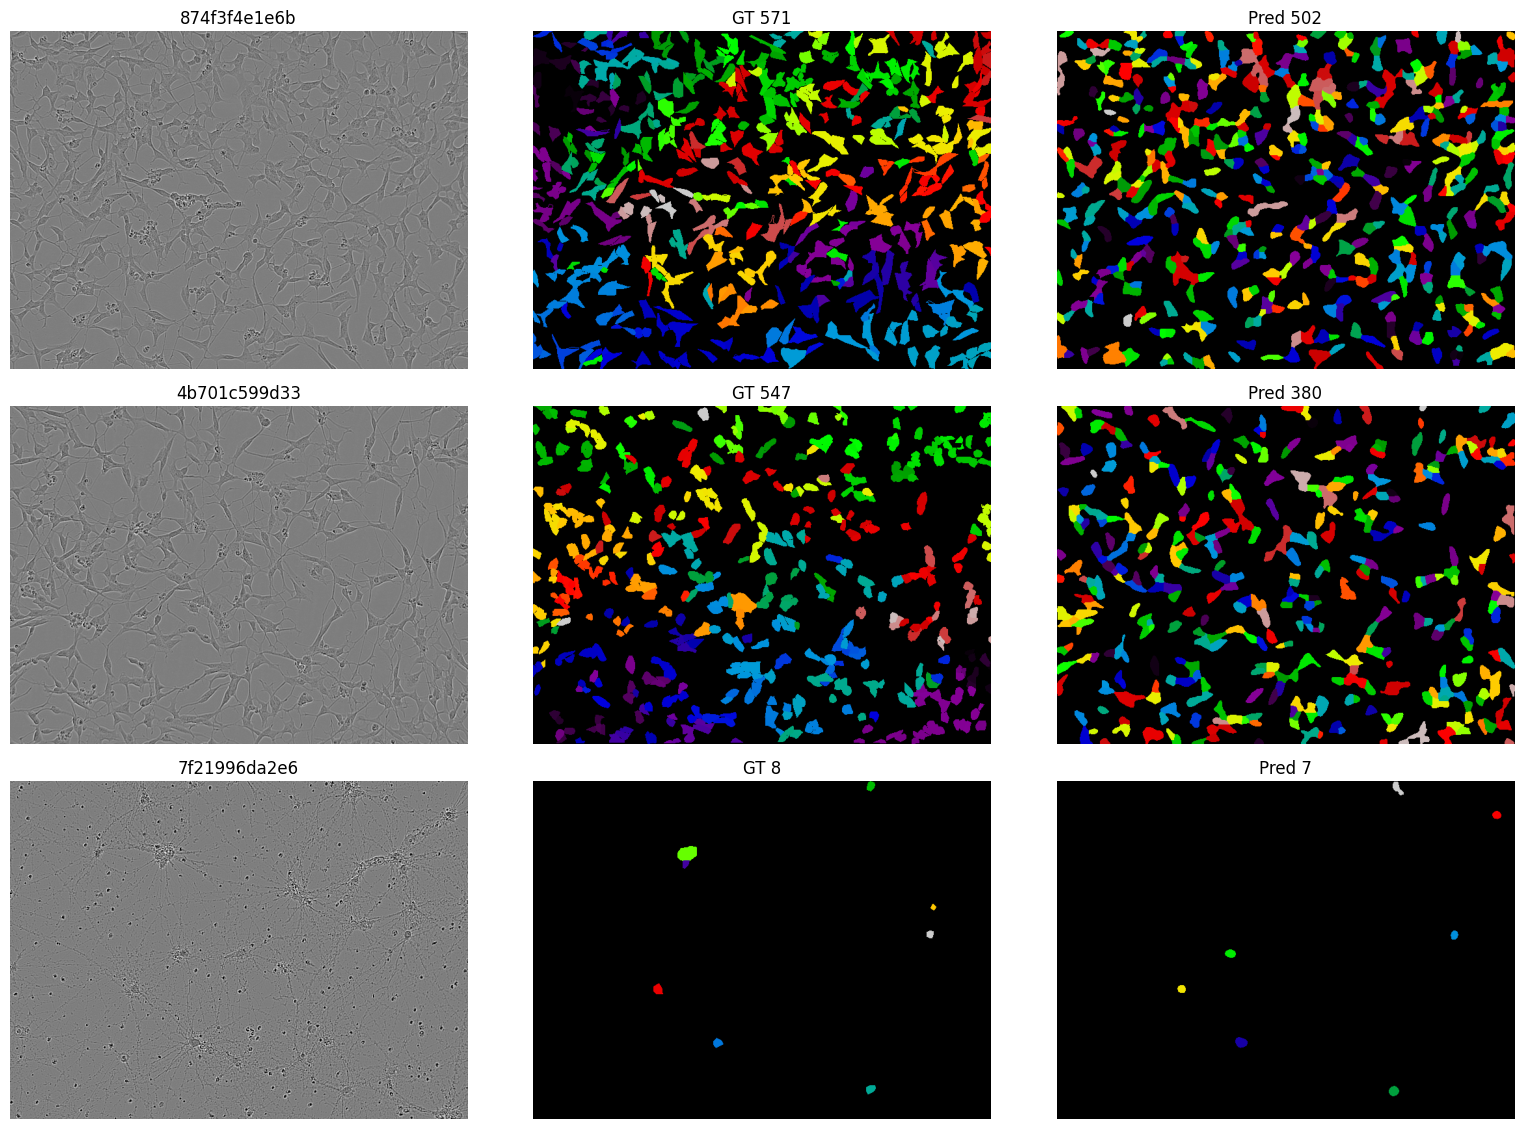

In [23]:
check_ids=sorted(val_ids,key=lambda i:-len(INST[i]))[:2]+sorted(val_ids,key=lambda i:len(INST[i]))[:1]
fig,axes=plt.subplots(len(check_ids),3,figsize=(16,3.8*len(check_ids)))
if len(check_ids)==1: axes=np.expand_dims(axes,0)
for r,image_id in enumerate(check_ids):
    image=IMAGES[image_id]
    p=VAL_MAPS[image_id].astype(np.float32)/255.0
    pred=decode_instances(p[0],p[1],POST["t_cell"],POST["t_seed"],POST["min_area"],POST["marker_mode"],POST["min_distance"])
    pred_lab=np.zeros((CFG.IMG_H,CFG.IMG_W),np.int32)
    for j,(_,flat) in enumerate(pred,1): pred_lab.reshape(-1)[flat]=j
    gt_lab=np.zeros_like(pred_lab)
    for j,flat in enumerate(INST[image_id],1): gt_lab.reshape(-1)[flat]=j
    axes[r,0].imshow(image,cmap="gray"); axes[r,0].set_title(image_id)
    axes[r,1].imshow(gt_lab,cmap="nipy_spectral"); axes[r,1].set_title(f"GT {len(INST[image_id])}")
    axes[r,2].imshow(pred_lab,cmap="nipy_spectral"); axes[r,2].set_title(f"Pred {len(pred)}")
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.show()

## 20 · Persist artifacts, report, and download

In [24]:
if CFG.SAVE_CACHES:
    with open(ART/"val_maps.pkl","wb") as f:
        pickle.dump({"maps":VAL_MAPS,"val_ids":val_ids,"post":POST,"f1":VAL_F1,"run_tag":CFG.RUN_TAG},f,protocol=4)
    with open(ART/"test_maps.pkl","wb") as f:
        pickle.dump(TEST_MAPS,f,protocol=4)

shutil.copy2(SELECTED_PATH,ART/"selected_model.pt")
shutil.copy2(SSL_ENCODER_PATH,ART/"ssl_encoder.pt")
shutil.copy2(SUB_PATH,ART/"submission.csv")
if ALT_PATH is not None and ALT_PATH.exists(): shutil.copy2(ALT_PATH,ART/"submission_alt.csv")

report=[
    "# Stage 6 report — SSL + Mean Teacher ConvNeXt-UNet watershed",
    f"- encoder: {CFG.ENCODER}",
    f"- unlabeled images used: {len(UNLABELED_PATHS)}",
    f"- selected checkpoint source: {STATS.get('selected_source')}",
    f"- supervised quick grouped F1: {STATS.get('supervised_quick_f1'):.4f}",
    f"- best semi-supervised quick grouped F1: {STATS.get('semi_quick_f1'):.4f}",
    f"- final TTA + tuned watershed grouped F1: {VAL_F1:.4f}",
    f"- post-processing: {POST}",
    f"- train/val images: {len(train_ids)}/{len(val_ids)} | groups: {STATS.get('n_groups')}",
    f"- max val-to-train thumbnail correlation: {STATS.get('max_val_train_corr'):.3f}",
    f"- test predictions/image: mean {main_info['mean_predictions']:.1f} (min {main_info['min']}, max {main_info['max']})",
    f"- fallbacks: {main_info['fallbacks']}",
    f"- total elapsed: {format_duration(elapsed_seconds())}",
    "",
    "## Interpretation",
    "The selected checkpoint is chosen only from grouped validation. The unlabeled data affect the model through",
    "self-supervised domain adaptation and conservative EMA teacher consistency. Hard pseudo-label polishing is",
    "disabled by default because it is higher risk and should only be accepted after a demonstrated validation gain.",
]
(ART/"REPORT.md").write_text("\n".join(report))
with open(ART/"stats.json","w") as f: json.dump(STATS,f,indent=2,default=str)

print("\n".join(report))
print("\nArtifacts:")
for p in sorted(ART.iterdir()):
    print(f"  {p.name:<28} {p.stat().st_size/1e6:7.1f} MB")

print("\nSuggested Kaggle description:")
print(f"Y_6th: ConvNeXt-UNet + watershed, SimSiam microscopy adaptation + EMA Mean Teacher on provided unlabeled data, grouped-val F1 {VAL_F1:.4f}, {POST['marker_mode']} markers, no ensemble.")

try:
    from google.colab import files
    files.download(str(SUB_PATH))
    if ALT_PATH is not None and ALT_PATH.exists(): files.download(str(ALT_PATH))
except Exception as e:
    print("Automatic browser download unavailable:",e)
    print("Submission copies are saved in",ART)

# Stage 6 report — SSL + Mean Teacher ConvNeXt-UNet watershed
- encoder: convnext_tiny.fb_in22k_ft_in1k
- unlabeled images used: 1972
- selected checkpoint source: supervised
- supervised quick grouped F1: 0.7539
- best semi-supervised quick grouped F1: 0.7539
- final TTA + tuned watershed grouped F1: 0.7740
- post-processing: {'t_cell': 0.5, 't_seed': 0.65, 'marker_mode': 'cc', 'min_distance': 0, 'min_area': 71}
- train/val images: 339/85 | groups: 424
- max val-to-train thumbnail correlation: 0.553
- test predictions/image: mean 102.9 (min 6, max 569)
- fallbacks: 0
- total elapsed: 1h 07m 52s

## Interpretation
The selected checkpoint is chosen only from grouped validation. The unlabeled data affect the model through
self-supervised domain adaptation and conservative EMA teacher consistency. Hard pseudo-label polishing is
disabled by default because it is higher risk and should only be accepted after a demonstrated validation gain.

Artifacts:
  REPORT.md                        0.0 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>